In [19]:
import networkx as nx
import matplotlib.pyplot as plt


In [20]:
# create an empty graph
G = nx.Graph()

# add nodes
for letter in ['A', 'B']:
  for num in range(1,2):
    G.add_nodes_from([f'{letter}{num}'])

# add edges
G.add_edges_from([
    ('A1', 'B1'),
    ('A2', 'B1'),
    ('A1', 'B2'),
    ('A1', 'A2')
    ])


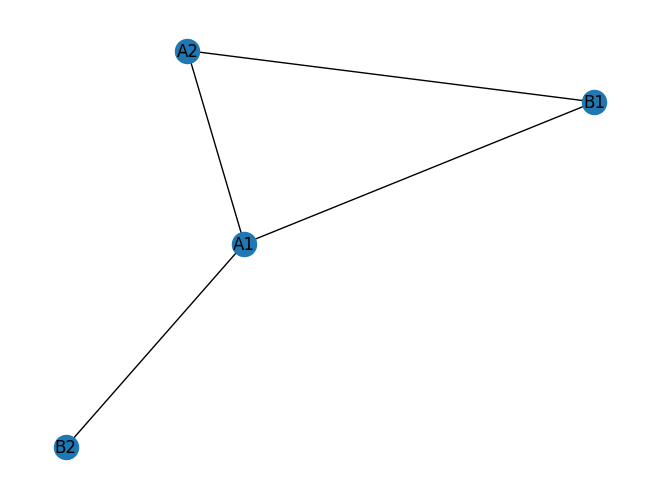

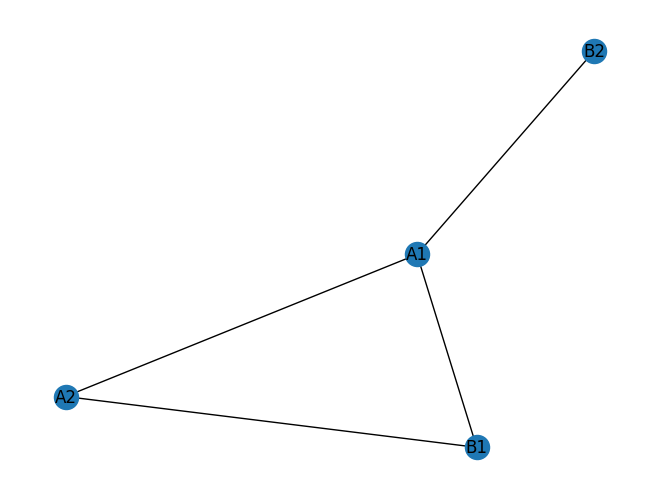

In [21]:
# draw the graph
nx.draw(G, with_labels=True)
plt.show()

# save graph to file
nx.write_gml(G, 'graph.gml')

# load graph from file
H = nx.read_gml('graph.gml')

# draw the graph
nx.draw(H, with_labels=True)
plt.show()


In [22]:
# print node degrees
for node in G.nodes():
  print(f'{node} has degree {G.degree(node)}')


A1 has degree 3
B1 has degree 2
A2 has degree 2
B2 has degree 1


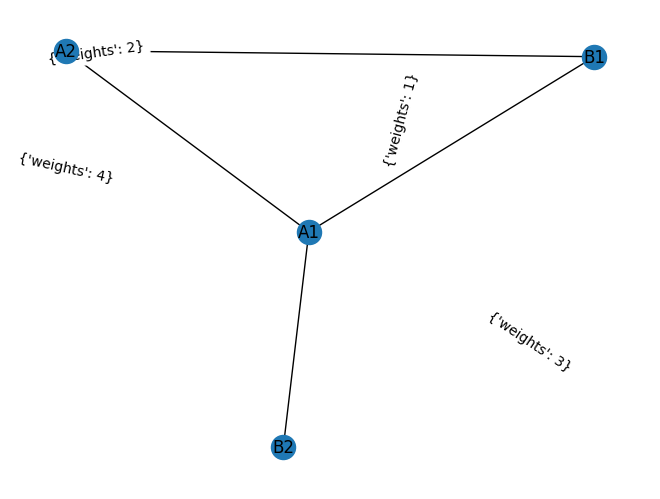

In [23]:
weights = {
    ('A1', 'B1'):1,
    ('A2', 'B1'):2,
    ('A1', 'B2'):3,
    ('A1', 'A2'):4
}

# add weights to edges
nx.set_edge_attributes(H, weights, 'weights')

# draw the graph
nx.draw(H, with_labels=True)
nx.draw_networkx_edge_labels(H, pos=nx.kamada_kawai_layout(H), edge_labels=None)
plt.show()


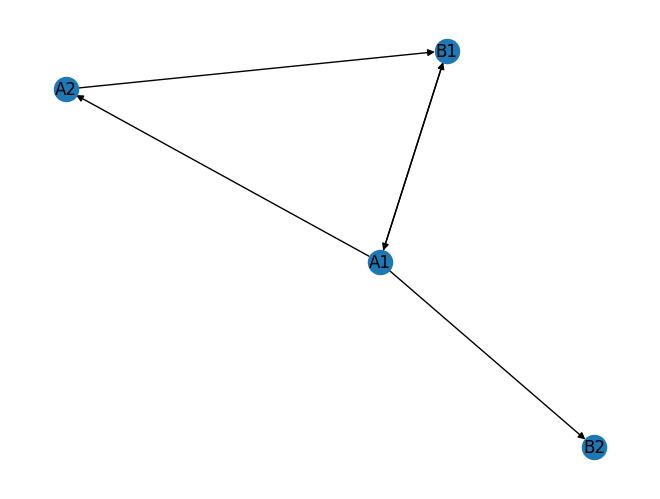

In [24]:
# directed graph
D = nx.DiGraph()

# add nodes
D.add_edges_from([
    ('A1', 'B1'),
    ('B1', 'A1'), # two way edge
    ('A2', 'B1'),
    ('A1', 'B2'),
    ('A1', 'A2')
    ])

nx.draw(D, pos=nx.kamada_kawai_layout(D), with_labels=True)
plt.show()


In [25]:
# node degrees
for node in D.nodes():
  print(f'{node} has out degree {D.out_degree(node)} and in degree {D.in_degree(node)}')


A1 has out degree 3 and in degree 1
B1 has out degree 1 and in degree 2
A2 has out degree 1 and in degree 1
B2 has out degree 0 and in degree 1


Exercícios

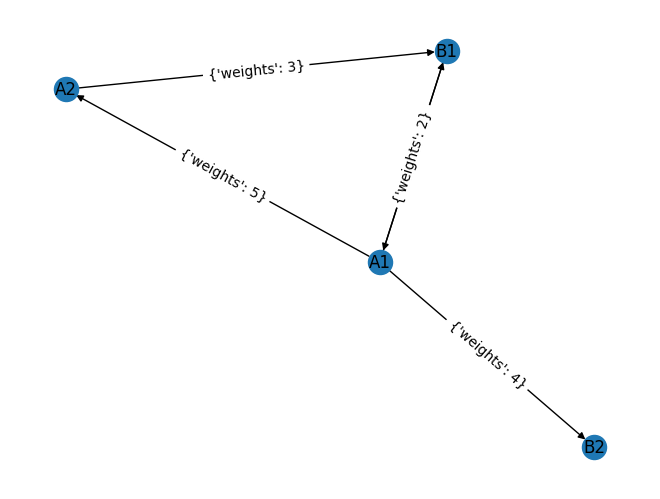

In [26]:
# add weights to the directed graph
weights = {
    ('A1', 'B1'):1,
    ('B1', 'A1'):2,
    ('A2', 'B1'):3,
    ('A1', 'B2'):4,
    ('A1', 'A2'):5
}

nx.set_edge_attributes(D, weights, 'weights')

# draw the graph
nx.draw(D, pos=nx.kamada_kawai_layout(D), with_labels=True)
nx.draw_networkx_edge_labels(D, pos=nx.kamada_kawai_layout(D), edge_labels=None)
plt.show()


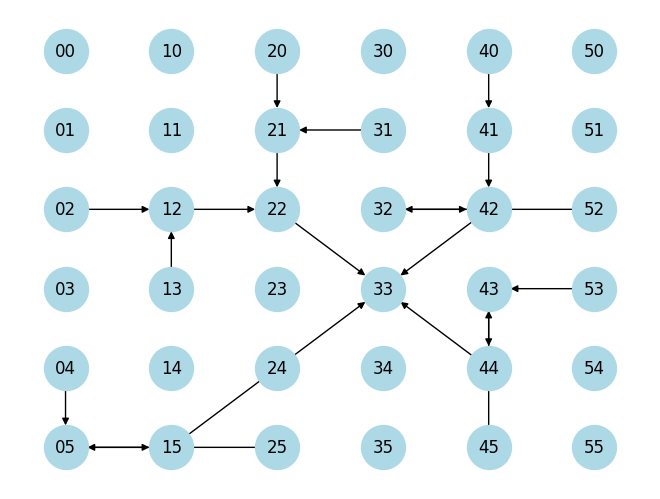

In [27]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# Rules:
# Choose a circle
# Move to the closest square
# Move to the closest triangle only at right or bottom
# Move to the closest square only diagonally

# Shapes distribution
shapes = np.array([
    ['square', 'triangle', 'circle', 'triangle', 'circle', 'square'],
    ['triangle', 'triangle', 'square', 'circle', 'square', 'triangle'],
    ['circle', 'square', 'triangle', 'square', 'triangle', 'circle'],
    ['triangle', 'circle', 'square', 'square', 'triangle', 'triangle'],
    ['circle', 'square', 'triangle', 'square', 'triangle', 'circle'],
    ['square', 'triangle', 'circle', 'circle', 'square', 'triangle']
])

# Create the graph following the rules

G = nx.DiGraph()


def find_closest_square(G, i, j):
    min_dist = float('inf')
    closest_square = []
    for x in range(6):
        for y in range(6):
            if shapes[x][y] == 'square':
                dist = abs(x - i) + abs(y - j)
                if dist < min_dist:
                    min_dist = dist
                    closest_square = (x, y)
    if not closest_square:
        return closest_square
    G.add_edge(f'{i}{j}', f'{closest_square[0]}{closest_square[1]}')
    return closest_square


def find_closest_triangle(G, i, j):
    min_dist = float('inf')
    closest_triangle = []
    for x in range(i, 6):
        for y in range(j, 6):
            if shapes[x][y] == 'triangle':
                dist = abs(x - i) + abs(y - j)
                if dist < min_dist:
                    min_dist = dist
                    closest_triangle = (x, y)
    if not closest_triangle:
        return closest_triangle
    G.add_edge(f'{i}{j}', f'{closest_triangle[0]}{closest_triangle[1]}')
    return closest_triangle


def find_closest_square_diagonally(G, i, j):
    min_dist = float('inf')
    closest_square = []
    for x in range(6):
        for y in range(6):
            if shapes[x][y] == 'square':
                dist = abs(x - i) + abs(y - j)
                if dist < min_dist and abs(x - i) == abs(y - j):
                    min_dist = dist
                    closest_square = (x, y)
    if not closest_square:
        return closest_square
    G.add_edge(f'{i}{j}', f'{closest_square[0]}{closest_square[1]}')
    return closest_square


for i in range(6):
    for j in range(6):
        G.add_node(f'{i}{j}', shape=shapes[i][j])

all_circles = [node for node in G.nodes if G.nodes[node]['shape'] == 'circle']

for circle in all_circles:
    i, j = int(circle[0]), int(circle[1])
    square = find_closest_square(G, i, j)
    triangle = find_closest_triangle(G, square[0], square[1])
    find_closest_square_diagonally(G, triangle[0], triangle[1])


pos = {f'{i}{j}': (i, -j) for i in range(6) for j in range(6)}

nx.draw(G, pos, with_labels=True, node_size=1000, node_color='lightblue')
plt.show()
